IMPORT LIBRARIES

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import heapq

Create the Robot Environment


In [ ]:
rows = 10
cols = 10

grid = np.zeros((rows, cols))

print(grid)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Add Start and Goal


In [ ]:
start = (0, 0)
goal = (9, 9)

print("Start:", start)
print("Goal:", goal)

Start: (0, 0)
Goal: (9, 9)


Add Obstacles

In [ ]:
obstacles = [
    (1, 2),
    (2, 2),
    (3, 2),
    (4, 2),
    (4, 3),
    (4, 4),
    (6, 5),
    (7, 5),
    (8, 5)
]

for obstacle in obstacles:
    grid[obstacle] = 1

print(grid)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Visualize the Environment

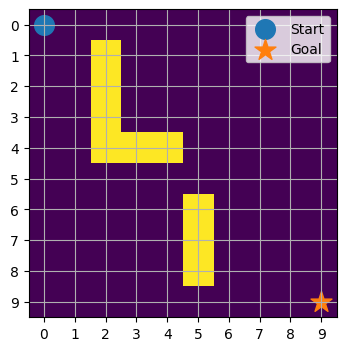

In [ ]:
plt.figure(figsize=(4, 4))

plt.imshow(grid)

plt.scatter(start[1], start[0], marker='o', s=200, label='Start')
plt.scatter(goal[1], goal[0], marker='*', s=250, label='Goal')

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.grid()
plt.legend()

plt.show()

**Define Robot Movements**

The robot should be able to move:
Up
Down
Left
Right

In [ ]:
actions = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1)     # Right
]

Check Valid Movements

In [ ]:
def is_valid(state):
    r, c = state

    if r < 0 or r >= rows:
        return False

    if c < 0 or c >= cols:
        return False

    if grid[r, c] == 1:
        return False

    return True

Find Neighboring States

In [ ]:
def get_neighbors(state):
    neighbors = []

    r, c = state

    for dr, dc in actions:
        new_state = (r + dr, c + dc)

        if is_valid(new_state):
            neighbors.append(new_state)

    return neighbors

Test the Robot's Neighbors

In [ ]:
state = (3, 3)

print("Current State:", state)
print("Possible Next States:", get_neighbors(state))

Current State: (3, 3)
Possible Next States: [(2, 3), (3, 4)]


Find a Basic Path

In [ ]:
from collections import deque

def bfs(start, goal):
    queue = deque([start])
    parent = {start: None}

    while queue:
        current = queue.popleft()

        if current == goal:
            break

        for next_state in get_neighbors(current):

            if next_state not in parent:
                parent[next_state] = current
                queue.append(next_state)

    if goal not in parent:
        return []

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return path

Generate the Path

In [ ]:
path = bfs(start, goal)

print("Path:")
print(path)

print("Path Length:", len(path))

Path:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
Path Length: 19


Visualize the Path

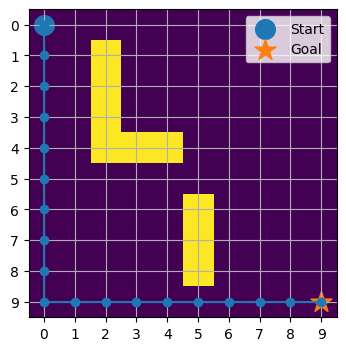

In [ ]:
plt.figure(figsize=(4, 4))

plt.imshow(grid)

path_rows = [p[0] for p in path]
path_cols = [p[1] for p in path]

plt.plot(path_cols, path_rows, marker='o')

plt.scatter(start[1], start[0], marker='o', s=200, label='Start')
plt.scatter(goal[1], goal[0], marker='*', s=250, label='Goal')

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.grid()
plt.legend()

plt.show()

PART 1 — Environment
       ↓
PART 2 — Basic Path Planning     ← YOU ARE HERE
       ↓
PART 3 — State Values
       ↓
PART 4 — Priority Queue
       ↓
PART 5 — Prioritized Sweeping
       ↓
PART 6 — Dynamic Obstacles
       ↓
PART 7 — Automatic Replanning
       ↓
PART 8 — Performance Comparison
       ↓
PART 9 — Final Visualization